# Lab 04 — The transformer block and TinyGPT

**Book sections:** [2.4 The block](../../book/docs/chapters/02-transformers/block.md),
[2.5 Training](../../book/docs/chapters/02-transformers/training.md),
[2.6 Inference](../../book/docs/chapters/02-transformers/inference.md),
[2.7 Scale](../../book/docs/chapters/02-transformers/scaling.md).

**Goal.** Build RMSNorm, SwiGLU and a pre-norm block; check them against the course's reference
implementation; count parameters; train a character-level decoder-only transformer on depot
instructions; reproduce the "no shift" bug; sample at different temperatures; implement and time a KV
cache.

**Runtime:** ≈1–2 minutes on CPU, ≈20 s on a GPU. **Seed:** 0.

In [1]:
import math
import time

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

from vlacourse import transformer as ref
from vlacourse.attention import MultiHeadAttention, causal_mask
from vlacourse.data.instructions import RUNNING_EXAMPLE, instruction_corpus
from vlacourse.seed import device, set_seed

set_seed(0)
dev = device()
print("device:", dev)

device: cuda


## 1. Components
RMSNorm: $\boldsymbol\gamma\odot\mathbf x/\sqrt{\mathrm{mean}(\mathbf x^2)+\epsilon}$, per token.
SwiGLU: $(\mathrm{SiLU}(\mathbf xW_1)\odot\mathbf xW_3)W_2$.

In [2]:
class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6):
        super().__init__()
        self.eps, self.weight = eps, nn.Parameter(torch.ones(d))

    def forward(self, x):                                   # (..., d)
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight


class SwiGLU(nn.Module):
    def __init__(self, d, d_ff):
        super().__init__()
        self.w1, self.w3 = nn.Linear(d, d_ff, bias=False), nn.Linear(d, d_ff, bias=False)
        self.w2 = nn.Linear(d_ff, d, bias=False)

    def forward(self, x):                                   # (..., d) -> (..., d)
        return self.w2(F.silu(self.w1(x)) * self.w3(x))


class Block(nn.Module):
    def __init__(self, d, n_heads, d_ff):
        super().__init__()
        self.norm1, self.attn = RMSNorm(d), MultiHeadAttention(d, n_heads)
        self.norm2, self.ffn = RMSNorm(d), SwiGLU(d, d_ff)

    def forward(self, x, mask=None):                        # (B, T, d)
        x = x + self.attn(self.norm1(x), mask=mask)         # mix across tokens
        return x + self.ffn(self.norm2(x))                  # transform each token


x = torch.randn(2, 5, 16) * 3
print("RMS per token after RMSNorm:", RMSNorm(16)(x).pow(2).mean(-1).sqrt()[0])

# Same weights in our block and in the reference block -> same outputs.
mine, theirs = Block(16, 4, 64), ref.Block(16, 4, 64)
theirs.load_state_dict(mine.state_dict())
m = causal_mask(5)
print("our block == reference block:", torch.allclose(mine(x, m), theirs(x, mask=m), atol=1e-6))

RMS per token after RMSNorm: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000], grad_fn=<SelectBackward0>)
our block == reference block: True


### The residual stream: each sub-layer adds a correction
Size of the stream vs. the size of what each sub-layer writes, at initialisation.

In [3]:
with torch.no_grad():
    h = torch.randn(1, 5, 16)
    a = mine.attn(mine.norm1(h), mask=m)
    f = mine.ffn(mine.norm2(h + a))
    print(f"|stream| {h.norm():.2f}   |attention write| {a.norm():.2f}   |FFN write| {f.norm():.2f}")

|stream| 9.44   |attention write| 1.93   |FFN write| 0.92


## 2. Data: characters of depot instructions
A character-level tokenizer keeps the lab self-contained; instructions are separated by newlines.

In [4]:
corpus = instruction_corpus(6000, seed=0)
train_text = "\n".join(corpus[:5400]) + "\n"
val_text = "\n".join(corpus[5400:]) + "\n"
chars = sorted(set(train_text + val_text))
stoi, itos = {c: i for i, c in enumerate(chars)}, chars
V = len(chars)
encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: "".join(itos[i] for i in ids)
train_ids = torch.tensor(encode(train_text))
val_ids = torch.tensor(encode(val_text))
print(f"V = {V} characters, {len(train_ids):,} training tokens")

CTX = 128


def get_batch(ids, B, gen):
    starts = torch.randint(0, len(ids) - CTX - 1, (B,), generator=gen)
    x = torch.stack([ids[s:s + CTX + 1] for s in starts])   # (B, CTX+1)
    return x.to(dev)

V = 35 characters, 256,681 training tokens


## 3. TinyGPT and its parameter count
We now use the packaged `vlacourse.transformer.TinyGPT` (built from the same block, with tied
embeddings, learned positions and a KV cache). Formula: $\approx 12Ld^2 + Vd + T_{\max}d$ — but SwiGLU
with $d_\text{ff}=4d$ has $3\cdot 4d^2=12d^2$ FFN parameters, so here a block is $16d^2$.

In [5]:
d, L, n_heads = 128, 4, 4
model = ref.TinyGPT(V, d=d, n_layers=L, n_heads=n_heads, max_len=CTX).to(dev)
n_params = sum(p.numel() for p in model.parameters())
formula = L * (4 * d * d + 3 * d * 4 * d + 2 * d) + V * d + CTX * d + d
print(f"parameters: {n_params:,}  formula: {formula:,}")
assert n_params == formula

parameters: 1,070,592  formula: 1,070,592


## 4. Training
Before training, the loss must be close to $\log V$ (a uniform guess). *This check caught a real bug while
this lab was written:* with PyTorch's default $\mathcal N(0,1)$ embedding initialisation and tied
input/output weights, the initial logits have standard deviation $\approx\sqrt d$ and the initial loss was
≈89 instead of 3.6. `TinyGPT` now initialises embeddings with std 0.02, as GPT-2 does. The shift: logits at position $t$
are compared with the token at $t+1$.

initial loss 3.574   log V = 3.555


step     0  train 3.574  val 3.451


step   250  train 0.268  val 0.268


step   500  train 0.239  val 0.246


step   750  train 0.226  val 0.240


step  1000  train 0.224  val 0.231


step  1250  train 0.223  val 0.229


step  1499  train 0.222  val 0.232
trained in 59 s


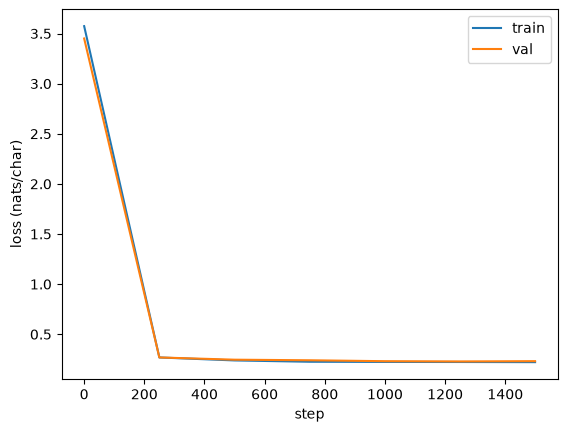

In [6]:
def lm_loss(model, xb, shift=True):
    if shift:
        logits = model(xb[:, :-1])                          # (B, CTX, V)
        targets = xb[:, 1:]                                 # (B, CTX)
    else:                                                   # THE BUG: predict the current token
        logits, targets = model(xb[:, :-1]), xb[:, :-1]
    return F.cross_entropy(logits.reshape(-1, V), targets.reshape(-1))


gen = torch.Generator().manual_seed(0)
with torch.no_grad():
    print(f"initial loss {lm_loss(model, get_batch(train_ids, 64, gen)).item():.3f}   log V = {math.log(V):.3f}")


def train(model, steps, shift=True, lr=3e-3, log_every=250):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, 0.95), weight_decay=0.1)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps, pct_start=0.1)
    gen, vgen = torch.Generator().manual_seed(0), torch.Generator().manual_seed(1)
    hist = []
    for step in range(steps):
        loss = lm_loss(model, get_batch(train_ids, 64, gen), shift)
        opt.zero_grad(set_to_none=True); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step()
        if step % log_every == 0 or step == steps - 1:
            with torch.no_grad():
                vl = lm_loss(model, get_batch(val_ids, 64, vgen), shift).item()
            hist.append((step, loss.item(), vl))
            print(f"step {step:5d}  train {loss.item():.3f}  val {vl:.3f}")
    return hist


t0 = time.time()
hist = train(model, 1500)
print(f"trained in {time.time() - t0:.0f} s")
s, tr, va = zip(*hist)
plt.plot(s, tr, label="train"); plt.plot(s, va, label="val"); plt.legend(); plt.xlabel("step")
plt.ylabel("loss (nats/char)"); plt.show()

## 5. The "no shift" bug
Train a fresh model where targets equal inputs. The loss collapses — and the model is useless.

In [7]:
set_seed(0)
buggy = ref.TinyGPT(V, d=d, n_layers=L, n_heads=n_heads, max_len=CTX).to(dev)
_ = train(buggy, 200, shift=False, log_every=100)
prompt = torch.tensor([encode("Bring the ")], device=dev)
print("buggy model generates:", repr(decode(buggy.generate(prompt, 40, temperature=0)[0].tolist())))

step     0  train 3.470  val 3.347


step   100  train 0.002  val 0.002


step   199  train 0.001  val 0.001
buggy model generates: 'Bring the                                         '


## 6. Sampling
Generate new instructions from a newline prompt at several temperatures and measure how many are
copies of training instructions vs. novel ones.

In [8]:
train_set = set(corpus[:5400])
model.eval()
for temp in [0.2, 0.8, 1.5]:
    g = torch.Generator(device=dev).manual_seed(0)
    lines = []
    for _ in range(8):   # 8 samples of CTX-1 characters each (learned positions cap the length)
        out = model.generate(torch.tensor([encode("\n")], device=dev), CTX - 1, temperature=temp, generator=g)
        lines += [l for l in decode(out[0].tolist()).split("\n")[1:-1] if l]   # complete lines only
    copied = sum(l in train_set for l in lines)
    print(f"--- temperature {temp}: {len(lines)} lines, {copied} copied from training data")
    for l in lines[:4]:
        print("   ", l)

--- temperature 0.2: 19 lines, 16 copied from training data
    The arm, fly to the inspection station and look for the green cone.
    Pick up the black crate.
    The arm, survey the loading bay.
    The drone, survey the storage rack.


--- temperature 0.8: 18 lines, 9 copied from training data
    Stack the green cable reel on the white pallet.
    The arm, cover the east yard while drone two searches the charging pad.
    Survey the depot, find the yellow pallet, and bring it to the charging pad.
    Pick up the green cone and place it at the depot.


--- temperature 1.5: 19 lines, 6 copied from training data
    All drones, hover above the orange cable reel.
    Find the green barrel near the north gate.
    Find the blue toolbox.
    Survey the depot, find the red panel, and bring it to the storage rack.


Low temperature: repetitive, mostly memorised lines. High temperature: novel but increasingly
ungrammatical. The same dial exists — with physical consequences — when actions are sampled.

## 7. KV cache
Cached and uncached greedy generation must produce identical tokens; caching avoids recomputing past
keys/values. (Our TinyGPT's learned positions limit sequences to `CTX` tokens.)

In [9]:
prompt_cpu = torch.tensor([encode(RUNNING_EXAMPLE[:20])])
n_new = CTX - prompt_cpu.shape[1]


def time_generate(m_, dname, use_cache):
    m_.generate(prompt_cpu.to(dname), 5, temperature=0, use_cache=use_cache)   # warm-up
    torch.cuda.synchronize() if dname == "cuda" else None
    t0 = time.perf_counter()
    out = m_.generate(prompt_cpu.to(dname), n_new, temperature=0, use_cache=use_cache)
    torch.cuda.synchronize() if dname == "cuda" else None
    return out, (time.perf_counter() - t0) * 1000


default_threads = torch.get_num_threads()
configs = [("cpu", default_threads), ("cpu", 4)] + ([("cuda", default_threads)] if dev.type == "cuda" else [])
for dname, threads in configs:
    torch.set_num_threads(threads)
    m_ = model.to(dname)
    (o0, t_nc), (o1, t_c) = time_generate(m_, dname, False), time_generate(m_, dname, True)
    assert torch.equal(o0, o1)
    print(f"{dname:4} threads={threads:2d}   no cache {t_nc:7.1f} ms   cache {t_c:7.1f} ms")
torch.set_num_threads(default_threads)
model.to(dev)
print(repr(decode(o1[0].tolist())))

cpu  threads=16   no cache   425.7 ms   cache   130.7 ms


cpu  threads= 4   no cache   236.0 ms   cache    97.1 ms


cuda threads=16   no cache   244.9 ms   cache   200.3 ms
'Survey the east yard, find the black pallet, and bring it to the fuel tank.\nThe drone, survey the north gate at ten meters.\nThe '


Outputs are identical in every configuration. Now look at the times — they contain a deployment lesson:

* With PyTorch's **default thread count** (all logical cores), CPU timings are noisy, and the cache's
  advantage can shrink or even invert — while writing this lab we measured the cached run at 4.1 s
  versus 0.36 s without cache in one session. Each cached step is a handful of tiny single-token
  matrix–vector products; splitting each across many threads can cost more in synchronisation than it
  saves. With 4 threads the cache gives a stable ≈2× speed-up. Re-run this cell a few times.
* On a GPU, a model this small is dominated by per-step kernel-launch overhead, so both variants take
  about the same time; the bandwidth arithmetic of book 2.6 only bites when weights and context are large.

Latency at batch size 1 — the robot's regime — is governed by overheads that throughput benchmarks hide.
Chapter 11 returns to this.

Cache memory for this model: $2\cdot L\cdot h\cdot d_h\cdot$ 4 bytes (fp32) per token.

In [10]:
print(f"KV cache: {2 * L * d * 4} bytes/token; for Llama-2-7B in bf16: {2 * 32 * 32 * 128 * 2:,} bytes/token")

KV cache: 4096 bytes/token; for Llama-2-7B in bf16: 524,288 bytes/token


## Exercises
1. Replace learned absolute positions by RoPE (Lab 02) inside `MultiHeadAttention` and retrain. Can the
   model now generate beyond `CTX` characters?
2. Train with post-norm blocks and 12 layers, without warm-up. Compare stability with pre-norm.
3. Add a loss mask so that only the *second half* of each instruction contributes to the loss (as a VLA
   trains only on action tokens). How do samples change?
4. Measure training throughput (tokens/s) and compare it with $6N$ FLOPs per token and your hardware's
   peak FLOP rate. What utilisation do you get, and why is it low for such a small model?